In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
import random
from __future__ import annotations
from collections.abc import Iterator, Iterable
%matplotlib inline

In [2]:
from graphviz import Digraph

def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(
        format='svg',
        graph_attr={'rankdir': 'LR'},  # LR = left to right; explicit bg since the notebook paints transparent SVGs white
        # dark-filled nodes with light text, mid-gray edges: readable on dark and light themes
        #node_attr={'style': 'filled', 'fillcolor': '#1e2430', 'color': '#9aa4b2',
        #           'fontcolor': '#e6e6e6', 'fontname': 'Helvetica'},
        #edge_attr={'color': '#9aa4b2', 'arrowsize': '0.8'},
    )

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name=uid + n._op, label=n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

```py
self.grad  += 1.0 * newval.grad
other.grad += 1.0 * newval.grad
```

Every `.grad` is measured against the final newvalput $L$ (the node `.backward()` is called on):

$$ \text{self.grad} = \frac{d \; L}{d \; \text{self}} \qquad \text{other.grad} = \frac{d \; L}{d \; \text{other}} $$

Here,

$$ \text{newval} \; = \; \text{self} + \text{other} $$

By the chain rule,

$$ \frac{d \; L}{d \; \text{self}} \; = \; \frac{d \; \text{newval}}{d \; \text{self}} \; \times \; \frac{d \; L}{d \; \text{newval}} \; = \; 1.0 \; \times \; \text{newval.grad} $$

Similarly,

$$ \frac{d \; L}{d \; \text{other}} \; = \; \frac{d \; \text{newval}}{d \; \text{other}} \; \times \; \frac{d \; L}{d \; \text{newval}} \; = \; 1.0 \; \times \; \text{newval.grad} $$

The `1.0` is the local derivative $\frac{d \; \text{newval}}{d \; \text{self}}$: addition passes any change straight through. The same holds for `other`.

`+=` instead of `=`: if `self` is used in more than one place, each use adds its own share of the gradient.

In [38]:
class Value:

    def __init__(self, data, _children: tuple[Value] = (), _op = '', label = ''):
        self.grad = 0.0
        self.data = data
        self._prev = set(_children)
        self._backward = lambda: None
        self._op = _op
        self.label = label

    @staticmethod
    def make_value(cls, some_instance, *args, **kwargs):
        if isinstance(some_instance, (int, float)):
            return Value(some_instance, *args, **kwargs)
        elif isinstance(some_instance, Iterable):
            return [Value.make_value(cls, item, *args, **kwargs) for item in some_instance]
        # other stuff
        else:
            raise TypeError("Expected (int, float) in given instance.")

    def __repr__(self):
        return f"Value(data={self.data}, label='{self.label}')"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        new_val = Value(self.data + other.data, _children = (self, other), _op = '+')

        def _backward():
            self.grad += 1.0 * new_val.grad
            other.grad += 1.0 * new_val.grad
        new_val._backward = _backward

        return new_val

    def __radd__(self, other):
        return self + other

    def __mul__(self, other: Value):
        other = other if isinstance(other, Value) else Value(other)
        new_val = Value(self.data * other.data, _children = (self, other), _op = '*')

        def _backward():
            self.grad += other.data * new_val.grad
            other.grad += self.data * new_val.grad
        new_val._backward = _backward

        return new_val

    def __rmul__(self, other):
        return self * other

    def __pow__(self, other):
        assert isinstance(other, (int, float))
        out = Value(self.data ** other, (self, ), f'pow({other})')

        def _backward():
            self.grad += other * (self.data ** (other - 1)) * out.grad
        out._backward = _backward

        return out

    def __truediv__(self, other):
        return self * other ** -1

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other)

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), 'exp')

        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward

        return out

    # activations
    def tanh(self):
        x = self.data
        t = (math.exp(2 * x) - 1) / (math.exp(2 * x) + 1)
        out = Value(t, (self, ), 'tanh')

        def _backward():
            self.grad += (1 - t ** 2) * out.grad
        out._backward = _backward

        return out

    def sig(self):
        x = self.data
        o = 1 / (1 + math.exp(-x))
        out = Value(o, (self, ), 'sig')

        def _backward():
            self.grad += o * (1 - o) * out.grad
        out._backward = _backward

        return out

    def backward(self):
        visited = set()
        children: list[Value] = []

        def visit(node):
            if not node in visited:
                visited.add(node)
                for child in node._prev: visit(child)
                children.append(node)
        visit(self)

        self.grad = 1.0 # d L / d L
        # calc all gradients
        for node in reversed(children):
            node._backward()

In [67]:
class Neuron:
    def __init__(self, dim=1, label=''):
        self.label = label
        self.w = [Value(random.uniform(-1, 1), label= f'{self.label}_w{i}') for i in range(dim)]
        self.b = Value(random.uniform(-1, 1), label = f'{self.label}_b')

    def __call__(self, x: list[Value]):
        assert len(x) == len(self.w), "dimension mismatch"
        
        # out = w * x + b
        out: Value = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        
        # activation: linear
        out = out.tanh()
        out.label = f'{self.label}'

        return out

    def parameters(self):
        return self.w + [self.b]

class Layer:
    def __init__(self, n=1, d=1, label = ''):
        self.label = label
        self.neurons = [Neuron(d, label= f'L{self.label}_N{i}') for i in range(n)]

    def __call__(self, x: list[Value]):
        out = [n(x) for n in self.neurons]
        return out if len(out) > 1 else out[0]

    def parameters(self):
        return [p for n in self.neurons for p in n.parameters()]
    
class MultiLayerPerceptron:
    def __init__(self, input_dim: int, neuron_layers: list[int], learning_rate: float = 0.01):
        info = [input_dim] + neuron_layers
        self.layers = [Layer(info[i + 1], info[i], label= f'{i}') for i in range(len(neuron_layers))]
        self.learning_rate = learning_rate

    def __call__(self, x: list[Value]) -> list[Value]:
        for l in self.layers:
            x = l(x)
        return x

    def parameters(self):
        return [p for l in self.layers for p in l.parameters()]

    def reset_grads(self):
        for p in self.parameters(): p.grad = 0.0

    def pred(self, xs):
        yhats = [self.__call__(x) for x in xs]
        return yhats

    def compute_loss(self, xs: list[list[Value]], ys: list[Value], backward=False) -> Value:
        yhats = self.pred(xs)
        loss: Value = sum([(yhats[i] - ys[i]) ** 2 for i in range(len(ys))])
        if backward: loss.backward()
        return loss

    def train(self, epoch=1):
        # must've computed loss or smth before calling this cuz grads exist
        for _ in range(epoch):
            for p in self.parameters():
                p.data += self.learning_rate * (-p.grad)


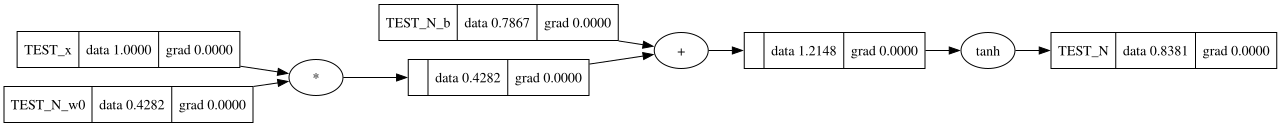

In [68]:
# test new stuff here
n1 = Neuron(1, 'TEST_N')
outp = n1([Value(1, label = 'TEST_x')])
draw_dot(outp)

In [41]:
nn = MultiLayerPerceptron(3, [2, 4, 4, 1])

In [42]:
# training

xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
] ; xs = Value.make_value(Value, xs, label = "x1")

ys = [1.0, -1.0, -1.0, 1.0] ; ys = Value.make_value(Value, ys, label = "y1")


In [65]:
loss = nn.compute_loss(xs, ys, True)
loss

Value(data=5.52778663656254e-06, label='')

In [63]:
for i in range(10000):
    nn.reset_grads()
    nn.compute_loss(xs, ys, True) # this does predictions and backward
    nn.train()

In [64]:
nn.pred(xs)

[Value(data=0.9990771248075159, label=''),
 Value(data=-0.9987562444054017, label=''),
 Value(data=-0.9986054096589934, label=''),
 Value(data=0.998911754707184, label='')]